# RQ1强化模型10：Random Forest集中优化

目标：在**不使用calibration和test选择参数**的前提下，系统强化Random Forest，并与FNN进行公平比较。

本Notebook分为四步：

1. 固定与RQ1一致的98维输入、144维输出和5个drifter folds；
2. 随机搜索树深度、叶节点大小、分裂样本数、特征比例和bootstrap样本比例；
3. 对前两名结构进一步选择树数量；
4. 使用3个随机种子拟合最终森林并平均预测，再在固定test set上评价。

与早期Notebook不同，超参数选择的主指标直接使用：

[
\mathrm{RMSE}_{72h}
=
\sqrt{\frac{1}{N}\sum_i e_{i,72}^{,2}},
]

其中 (e_{i,72}) 是validation case第72小时的Haversine separation error。

In [1]:
from pathlib import Path
import json
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, ParameterSampler

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "processed").exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("找不到data/processed；请从项目目录或其子目录运行。")

PROCESSED = PROJECT_ROOT / "data" / "processed"
OUTPUT_DIR = PROJECT_ROOT / "output" / "rq1" / "zh"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EARTH_RADIUS_KM = 6371.0
HISTORY_HOURS = 24
HORIZON_HOURS = 72
RANDOM_STATE = 2026
FAST_MODE = os.getenv("RQ1_FAST_MODE", "0") == "1"

plt.rcParams["font.sans-serif"] = ["PingFang SC", "Arial Unicode MS", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

print("项目目录：", PROJECT_ROOT)
print("快速检查模式：", FAST_MODE)

项目目录： /Users/roger/Documents/data3001-project
快速检查模式： False


## 1. 构造固定输入和输出

输入与Ridge、FNN、KNN以及基础Random Forest完全相同：

- origin latitude和longitude：2维；
- 过去24小时的相对东向位移、北向位移、东向速度和北向速度：(24\times4=96)维；
- 合计98维。

输出为未来72小时相对origin的东向和北向位移，共144维。

In [2]:
def latlon_to_local_km(origin_lat, origin_lon, latitude, longitude):
    lat0 = np.deg2rad(np.asarray(origin_lat, dtype=float))
    lon0 = np.deg2rad(np.asarray(origin_lon, dtype=float))
    lat1 = np.deg2rad(np.asarray(latitude, dtype=float))
    lon1 = np.deg2rad(np.asarray(longitude, dtype=float))
    dlon = (lon1 - lon0 + np.pi) % (2 * np.pi) - np.pi
    dlat = lat1 - lat0
    a = np.sin(dlat / 2) ** 2 + np.cos(lat0) * np.cos(lat1) * np.sin(dlon / 2) ** 2
    central = 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
    bearing = np.arctan2(
        np.sin(dlon) * np.cos(lat1),
        np.cos(lat0) * np.sin(lat1) - np.sin(lat0) * np.cos(lat1) * np.cos(dlon),
    )
    distance = EARTH_RADIUS_KM * central
    return distance * np.sin(bearing), distance * np.cos(bearing)


def local_km_to_latlon(origin_lat, origin_lon, east_km, north_km):
    lat0 = np.deg2rad(np.asarray(origin_lat, dtype=float))
    lon0 = np.deg2rad(np.asarray(origin_lon, dtype=float))
    east = np.asarray(east_km, dtype=float)
    north = np.asarray(north_km, dtype=float)
    distance = np.hypot(east, north)
    bearing = np.arctan2(east, north)
    angular = distance / EARTH_RADIUS_KM
    latitude = np.arcsin(
        np.sin(lat0) * np.cos(angular)
        + np.cos(lat0) * np.sin(angular) * np.cos(bearing)
    )
    longitude = lon0 + np.arctan2(
        np.sin(bearing) * np.sin(angular) * np.cos(lat0),
        np.cos(angular) - np.sin(lat0) * np.sin(latitude),
    )
    return np.rad2deg(latitude), (np.rad2deg(longitude) + 180) % 360 - 180


def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(
        lambda x: np.deg2rad(np.asarray(x, dtype=float)),
        [lat1, lon1, lat2, lon2],
    )
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(np.clip(a, 0, 1)))


origins = (
    pd.read_parquet(PROCESSED / "forecast_origins.parquet")
    .sort_values("forecast_case_id")
    .reset_index(drop=True)
)
observations = pd.read_parquet(
    PROCESSED / "region_A_observations.parquet",
    columns=["ID", "segment_id", "segment_step", "latitude", "longitude", "ve", "vn"],
)
n_cases = len(origins)

history = origins[[
    "forecast_case_id", "ID", "segment_id", "history_start_step",
    "origin_latitude", "origin_longitude",
]].loc[origins.index.repeat(HISTORY_HOURS)].reset_index(drop=True)
history["history_index"] = np.tile(np.arange(HISTORY_HOURS), n_cases)
history["segment_step"] = history["history_start_step"] + history["history_index"]
history = history.merge(
    observations,
    on=["ID", "segment_id", "segment_step"],
    how="left",
    validate="many_to_one",
).sort_values(["forecast_case_id", "history_index"]).reset_index(drop=True)
history["east_km"], history["north_km"] = latlon_to_local_km(
    history["origin_latitude"], history["origin_longitude"],
    history["latitude"], history["longitude"],
)
history_values = history[["east_km", "north_km", "ve", "vn"]].to_numpy().reshape(
    n_cases, HISTORY_HOURS, 4
)
X = np.column_stack([
    origins["origin_latitude"].to_numpy(),
    origins["origin_longitude"].to_numpy(),
    history_values.reshape(n_cases, -1),
])

targets = origins[[
    "forecast_case_id", "ID", "segment_id", "target_start_step",
    "origin_latitude", "origin_longitude",
]].loc[origins.index.repeat(HORIZON_HOURS)].reset_index(drop=True)
targets["lead_time_hours"] = np.tile(np.arange(1, HORIZON_HOURS + 1), n_cases)
targets["segment_step"] = targets["target_start_step"] + targets["lead_time_hours"] - 1
targets = targets.merge(
    observations[["ID", "segment_id", "segment_step", "latitude", "longitude"]],
    on=["ID", "segment_id", "segment_step"],
    how="left",
    validate="many_to_one",
).sort_values(["forecast_case_id", "lead_time_hours"]).reset_index(drop=True)
targets["east_km"], targets["north_km"] = latlon_to_local_km(
    targets["origin_latitude"], targets["origin_longitude"],
    targets["latitude"], targets["longitude"],
)
Y = targets[["east_km", "north_km"]].to_numpy().reshape(n_cases, 144)

train_idx = np.flatnonzero(origins["partition"].eq("training").to_numpy())
calibration_idx = np.flatnonzero(origins["partition"].eq("calibration").to_numpy())
test_idx = np.flatnonzero(origins["partition"].eq("test").to_numpy())
groups = origins["ID"].to_numpy()

checks = pd.Series({
    "cases=5117": n_cases == 5117,
    "X=5117×98": X.shape == (5117, 98),
    "Y=5117×144": Y.shape == (5117, 144),
    "training=3591": len(train_idx) == 3591,
    "calibration=769": len(calibration_idx) == 769,
    "test=757": len(test_idx) == 757,
    "无缺失或无限值": np.isfinite(X).all() and np.isfinite(Y).all(),
}, name="通过")
display(checks.to_frame())
assert checks.all()

,通过
cases=5117,True
X=5117×98,True
Y=5117×144,True
training=3591,True
calibration=769,True
test=757,True
无缺失或无限值,True


## 2. 固定drifter-grouped folds和精确72小时评分

所有候选模型使用完全相同的5个fold。评分函数先把第72小时预测位移还原成经纬度，再计算Haversine RMSE，因此优化目标与最终报告指标一致。

In [3]:
group_cv = GroupKFold(n_splits=5)
fixed_folds = [
    (train_idx[fit_local], train_idx[valid_local])
    for fit_local, valid_local in group_cv.split(
        X[train_idx], Y[train_idx], groups=groups[train_idx]
    )
]

fold_table = pd.DataFrame({
    "fold": np.arange(1, 6),
    "fit_cases": [len(a) for a, _ in fixed_folds],
    "validation_cases": [len(b) for _, b in fixed_folds],
    "validation_drifters": [origins.iloc[b]["ID"].nunique() for _, b in fixed_folds],
})
display(fold_table)

for fit_idx, valid_idx in fixed_folds:
    assert set(origins.iloc[fit_idx]["ID"]).isdisjoint(set(origins.iloc[valid_idx]["ID"]))


def endpoint_errors(indices, predictions):
    predictions = np.asarray(predictions)
    pred_east = predictions[:, -2]
    pred_north = predictions[:, -1]
    case_origins = origins.iloc[indices]
    pred_lat, pred_lon = local_km_to_latlon(
        case_origins["origin_latitude"].to_numpy(),
        case_origins["origin_longitude"].to_numpy(),
        pred_east,
        pred_north,
    )
    true_last = Y[indices][:, -2:]
    true_lat, true_lon = local_km_to_latlon(
        case_origins["origin_latitude"].to_numpy(),
        case_origins["origin_longitude"].to_numpy(),
        true_last[:, 0],
        true_last[:, 1],
    )
    return haversine_km(pred_lat, pred_lon, true_lat, true_lon)


def evaluate_configuration(params, n_estimators, random_state):
    rows = []
    for fold, (fit_idx, valid_idx) in enumerate(fixed_folds, start=1):
        model = RandomForestRegressor(
            n_estimators=n_estimators,
            bootstrap=True,
            random_state=random_state + fold,
            n_jobs=-1,
            **params,
        )
        model.fit(X[fit_idx], Y[fit_idx])
        pred = model.predict(X[valid_idx])
        errors = endpoint_errors(valid_idx, pred)
        rows.append({
            "fold": fold,
            "validation_cases": len(valid_idx),
            "rmse_72h_km": np.sqrt(np.mean(errors ** 2)),
            "median_72h_km": np.median(errors),
            "trajectory_displacement_rmse_km": np.sqrt(np.mean((pred - Y[valid_idx]) ** 2)),
        })
    return pd.DataFrame(rows)

,fold,fit_cases,validation_cases,validation_drifters
0,1,2872,719,63
1,2,2873,718,62
2,3,2873,718,62
3,4,2873,718,62
4,5,2873,718,62


## 3. 第一阶段：随机搜索结构参数

完整模式随机抽取20组结构，每组使用80棵树和固定5折CV。此阶段主要筛除明显较差的结构，不使用test set。

In [4]:
parameter_space = {
    "max_depth": [None, 10, 14, 18, 24, 32, 40],
    "min_samples_leaf": [1, 2, 3, 4, 6, 8, 12],
    "min_samples_split": [2, 4, 8, 12, 20],
    "max_features": [0.25, 0.4, 0.55, 0.7, 0.85, 1.0, "sqrt"],
    "max_samples": [0.6, 0.75, 0.9, None],
}
n_candidates = 3 if FAST_MODE else 20
stage1_trees = 25 if FAST_MODE else 80
candidates = list(ParameterSampler(
    parameter_space,
    n_iter=n_candidates,
    random_state=RANDOM_STATE,
))

stage1_rows = []
start = time.time()
for candidate_id, params in enumerate(candidates, start=1):
    fold_result = evaluate_configuration(params, stage1_trees, RANDOM_STATE)
    fold_result["candidate"] = candidate_id
    for key, value in params.items():
        fold_result[key] = value
    stage1_rows.append(fold_result)
    print(
        f"{candidate_id:02d}/{len(candidates)} "
        f"RMSE72={fold_result['rmse_72h_km'].mean():.3f} km | {params}"
    )

stage1_folds = pd.concat(stage1_rows, ignore_index=True)
stage1_summary = (
    stage1_folds.groupby("candidate", as_index=False)
    .agg(
        mean_cv_rmse_72h_km=("rmse_72h_km", "mean"),
        std_cv_rmse_72h_km=("rmse_72h_km", "std"),
        mean_cv_median_72h_km=("median_72h_km", "mean"),
        mean_trajectory_rmse_km=("trajectory_displacement_rmse_km", "mean"),
    )
    .merge(
        stage1_folds.drop_duplicates("candidate")[[
            "candidate", "max_depth", "min_samples_leaf", "min_samples_split",
            "max_features", "max_samples",
        ]],
        on="candidate",
    )
    .sort_values("mean_cv_rmse_72h_km")
    .reset_index(drop=True)
)
display(stage1_summary.head(10).round(3))
print(f"第一阶段耗时：{time.time()-start:.1f}秒")

01/20 RMSE72=68.067 km | {'min_samples_split': 2, 'min_samples_leaf': 12, 'max_samples': 0.75, 'max_features': 0.55, 'max_depth': 14}


02/20 RMSE72=67.508 km | {'min_samples_split': 20, 'min_samples_leaf': 6, 'max_samples': 0.9, 'max_features': 1.0, 'max_depth': None}


03/20 RMSE72=68.069 km | {'min_samples_split': 12, 'min_samples_leaf': 2, 'max_samples': 0.6, 'max_features': 0.4, 'max_depth': 32}


04/20 RMSE72=68.127 km | {'min_samples_split': 2, 'min_samples_leaf': 8, 'max_samples': 0.6, 'max_features': 0.4, 'max_depth': 14}


05/20 RMSE72=67.562 km | {'min_samples_split': 8, 'min_samples_leaf': 1, 'max_samples': 0.75, 'max_features': 0.85, 'max_depth': 40}


06/20 RMSE72=67.435 km | {'min_samples_split': 4, 'min_samples_leaf': 8, 'max_samples': 0.75, 'max_features': 1.0, 'max_depth': 32}


... (12 outputs left out)

19/20 RMSE72=68.813 km | {'min_samples_split': 4, 'min_samples_leaf': 2, 'max_samples': 0.9, 'max_features': 'sqrt', 'max_depth': None}


20/20 RMSE72=67.953 km | {'min_samples_split': 12, 'min_samples_leaf': 12, 'max_samples': 0.6, 'max_features': 0.85, 'max_depth': 24}


,candidate,mean_cv_rmse_72h_km,std_cv_rmse_72h_km,mean_cv_median_72h_km,mean_trajectory_rmse_km,max_depth,min_samples_leaf,min_samples_split,max_features,max_samples
0,6,67.435,3.464,46.638,26.897,32,8,4,1.0,0.75
1,18,67.444,3.284,46.330,26.912,24,8,20,1.0,0.9
2,2,67.508,3.249,46.455,26.933,None,6,20,1.0,0.9
3,5,67.562,3.470,46.519,26.933,40,1,8,0.85,0.75
4,12,67.595,3.451,46.425,26.979,24,4,20,0.85,0.75
5,16,67.639,3.530,46.937,27.015,14,12,4,0.85,None
6,14,67.724,3.487,46.764,27.039,40,2,20,1.0,0.75
7,8,67.747,3.477,46.582,27.053,10,6,20,0.7,0.75
8,11,67.900,3.641,46.453,27.125,14,12,2,1.0,0.6
9,20,67.953,3.605,46.496,27.148,24,12,12,0.85,0.6


第一阶段耗时：194.2秒


## 4. 第二阶段：优胜结构 × 树数量

取第一阶段前两名结构，比较150、350和600棵树。这样可以判断性能是否已经随树数量收敛，而不是任意指定400棵树。

In [5]:
top_n = 1 if FAST_MODE else 2
tree_counts = [30, 60] if FAST_MODE else [150, 350, 600]
top_candidate_ids = stage1_summary.head(top_n)["candidate"].astype(int).tolist()

stage2_rows = []
start = time.time()
for candidate_id in top_candidate_ids:
    params = candidates[candidate_id - 1]
    for n_trees in tree_counts:
        fold_result = evaluate_configuration(params, n_trees, RANDOM_STATE + 100)
        fold_result["candidate"] = candidate_id
        fold_result["n_estimators"] = n_trees
        for key, value in params.items():
            fold_result[key] = value
        stage2_rows.append(fold_result)
        print(
            f"candidate={candidate_id}, trees={n_trees}, "
            f"RMSE72={fold_result['rmse_72h_km'].mean():.3f} km"
        )

stage2_folds = pd.concat(stage2_rows, ignore_index=True)
stage2_summary = (
    stage2_folds.groupby(["candidate", "n_estimators"], as_index=False)
    .agg(
        mean_cv_rmse_72h_km=("rmse_72h_km", "mean"),
        std_cv_rmse_72h_km=("rmse_72h_km", "std"),
        mean_cv_median_72h_km=("median_72h_km", "mean"),
        mean_trajectory_rmse_km=("trajectory_displacement_rmse_km", "mean"),
    )
    .sort_values(["mean_cv_rmse_72h_km", "mean_trajectory_rmse_km"])
    .reset_index(drop=True)
)
display(stage2_summary.round(3))
best_stage2 = stage2_summary.iloc[0]
best_candidate = int(best_stage2["candidate"])
best_n_estimators = int(best_stage2["n_estimators"])
best_params = candidates[best_candidate - 1]
print("最终结构：", best_params)
print("树数量：", best_n_estimators)
print(f"第二阶段耗时：{time.time()-start:.1f}秒")

candidate=6, trees=150, RMSE72=67.381 km


candidate=6, trees=350, RMSE72=67.373 km


candidate=6, trees=600, RMSE72=67.347 km


candidate=18, trees=150, RMSE72=67.448 km


candidate=18, trees=350, RMSE72=67.370 km


candidate=18, trees=600, RMSE72=67.328 km


,candidate,n_estimators,mean_cv_rmse_72h_km,std_cv_rmse_72h_km,mean_cv_median_72h_km,mean_trajectory_rmse_km
0,18,600,67.328,3.442,46.498,26.861
1,6,600,67.347,3.496,46.506,26.865
2,18,350,67.370,3.457,46.539,26.880
3,6,350,67.373,3.457,46.543,26.875
4,6,150,67.381,3.423,46.498,26.886
5,18,150,67.448,3.456,46.728,26.924


最终结构： {'min_samples_split': 20, 'min_samples_leaf': 8, 'max_samples': 0.9, 'max_features': 1.0, 'max_depth': 24}
树数量： 600
第二阶段耗时：430.6秒


## 5. 使用3个随机种子建立最终稳定集成

参数确定后，用全部training cases分别拟合3个不同随机种子的Random Forest，并平均预测。这个平均不使用test outcome决定权重，每个成员权重均为 (1/3)。

In [6]:
final_seeds = [2026] if FAST_MODE else [2026, 2037, 2048]
test_predictions = []
start = time.time()

for seed in final_seeds:
    model = RandomForestRegressor(
        n_estimators=best_n_estimators,
        bootstrap=True,
        random_state=seed,
        n_jobs=-1,
        **best_params,
    )
    model.fit(X[train_idx], Y[train_idx])
    test_predictions.append(model.predict(X[test_idx]))
    print("完成seed：", seed)

y_pred_test = np.mean(test_predictions, axis=0)
print("集成预测形状：", y_pred_test.shape)
print(f"最终拟合耗时：{time.time()-start:.1f}秒")

完成seed： 2026


完成seed： 2037


完成seed： 2048
集成预测形状： (757, 144)
最终拟合耗时：99.3秒


## 6. 固定test set上的完整评价

以下test结果只在所有参数和集成规则冻结后计算。

In [7]:
def evaluate_test(y_pred):
    y_pred = np.asarray(y_pred).reshape(len(test_idx), HORIZON_HOURS, 2)
    test_origins = origins.iloc[test_idx].reset_index(drop=True)
    origin_lat = np.repeat(test_origins["origin_latitude"].to_numpy(), HORIZON_HOURS)
    origin_lon = np.repeat(test_origins["origin_longitude"].to_numpy(), HORIZON_HOURS)
    pred_lat, pred_lon = local_km_to_latlon(
        origin_lat, origin_lon,
        y_pred[:, :, 0].reshape(-1),
        y_pred[:, :, 1].reshape(-1),
    )
    test_targets = (
        targets[targets["forecast_case_id"].isin(test_origins["forecast_case_id"])]
        .sort_values(["forecast_case_id", "lead_time_hours"])
        .reset_index(drop=True)
    )
    evaluation = pd.DataFrame({
        "forecast_case_id": np.repeat(test_origins["forecast_case_id"].to_numpy(), HORIZON_HOURS),
        "ID": np.repeat(test_origins["ID"].to_numpy(), HORIZON_HOURS),
        "lead_time_hours": np.tile(np.arange(1, HORIZON_HOURS + 1), len(test_origins)),
        "pred_latitude": pred_lat,
        "pred_longitude": pred_lon,
        "true_latitude": test_targets["latitude"].to_numpy(),
        "true_longitude": test_targets["longitude"].to_numpy(),
    })
    evaluation["separation_error_km"] = haversine_km(
        evaluation["pred_latitude"], evaluation["pred_longitude"],
        evaluation["true_latitude"], evaluation["true_longitude"],
    )
    lead_metrics = (
        evaluation.groupby("lead_time_hours")["separation_error_km"]
        .agg(
            n="size",
            median_error_km="median",
            q25_error_km=lambda x: x.quantile(0.25),
            q75_error_km=lambda x: x.quantile(0.75),
            rmse_km=lambda x: np.sqrt(np.mean(np.square(x))),
        )
        .reset_index()
    )
    case_rows = []
    for case_id, frame in evaluation.groupby("forecast_case_id", sort=False):
        frame = frame.sort_values("lead_time_hours")
        errors = frame["separation_error_km"].to_numpy()
        case_rows.append({
            "forecast_case_id": case_id,
            "ID": frame["ID"].iloc[0],
            "final_72h_error_km": errors[-1],
            "integrated_trajectory_error_km_h": np.trapezoid(
                np.r_[0.0, errors],
                x=np.r_[0, frame["lead_time_hours"].to_numpy()],
            ),
        })
    return evaluation, lead_metrics, pd.DataFrame(case_rows)

evaluation, lead_metrics, case_metrics = evaluate_test(y_pred_test)

def metric(hour, column):
    return float(lead_metrics.loc[lead_metrics["lead_time_hours"].eq(hour), column].iloc[0])

summary = pd.DataFrame({
    "指标": [
        "Training cases", "Calibration cases（未使用）", "Test cases",
        "24h median error (km)", "48h median error (km)",
        "72h median error (km)", "72h RMSE (km)", "Median ITE (km·h)",
    ],
    "结果": [
        len(train_idx), len(calibration_idx), len(test_idx),
        metric(24, "median_error_km"), metric(48, "median_error_km"),
        metric(72, "median_error_km"), metric(72, "rmse_km"),
        case_metrics["integrated_trajectory_error_km_h"].median(),
    ],
})
display(summary.round(3))

,指标,结果
0,Training cases,3591.000
1,Calibration cases（未使用）,769.000
2,Test cases,757.000
3,24h median error (km),11.442
4,48h median error (km),25.864
5,72h median error (km),41.887
6,72h RMSE (km),62.173
7,Median ITE (km·h),1414.577


## 7. 与FNN及两个物理基线比较

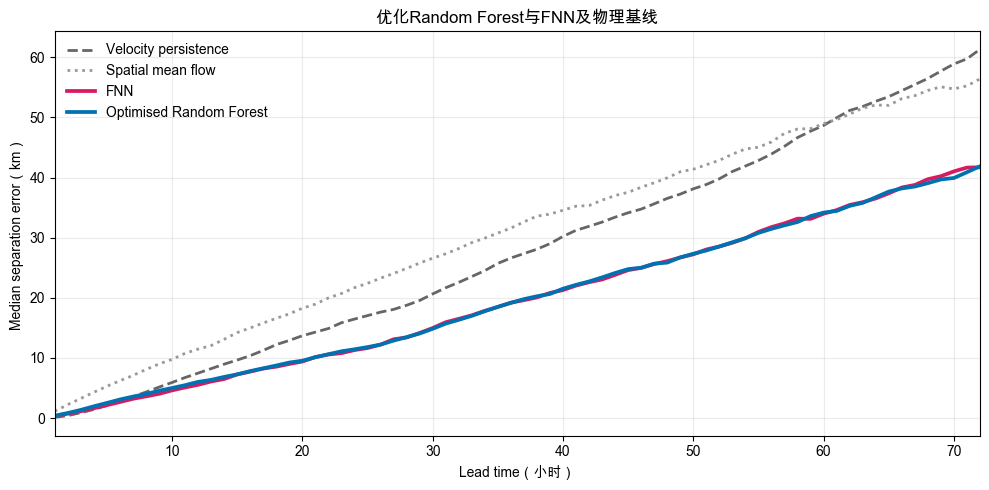

,model,median_72h_km,rmse_72h_km
2,FNN,41.716,62.150
3,Optimised Random Forest,41.887,62.173
1,Spatial mean flow,56.422,80.978
0,Velocity persistence,61.347,90.101


In [8]:
comparison_sources = {
    "Velocity persistence": pd.read_csv(OUTPUT_DIR / "velocity_persistence_lead_metrics.csv"),
    "Spatial mean flow": pd.read_csv(OUTPUT_DIR / "spatial_mean_flow_lead_metrics.csv"),
    "FNN": pd.read_csv(OUTPUT_DIR / "fnn_lead_metrics.csv"),
    "Optimised Random Forest": lead_metrics,
}

fig, ax = plt.subplots(figsize=(10, 5))
styles = {
    "Velocity persistence": ("#666666", "--"),
    "Spatial mean flow": ("#999999", ":"),
    "FNN": ("#d81b60", "-"),
    "Optimised Random Forest": ("#0072b2", "-"),
}
for name, frame in comparison_sources.items():
    color, linestyle = styles[name]
    ax.plot(
        frame["lead_time_hours"], frame["median_error_km"],
        color=color, linestyle=linestyle,
        linewidth=2.7 if name in ["FNN", "Optimised Random Forest"] else 2,
        label=name,
    )
ax.set(
    xlabel="Lead time（小时）",
    ylabel="Median separation error（km）",
    title="优化Random Forest与FNN及物理基线",
)
ax.set_xlim(1, 72)
ax.grid(alpha=0.25)
ax.legend(frameon=False)
plt.tight_layout()
fig.savefig(
    OUTPUT_DIR / "optimised_random_forest_vs_fnn_and_baselines.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

rows = []
for name, frame in comparison_sources.items():
    row = frame.loc[frame["lead_time_hours"].eq(72)].iloc[0]
    rows.append({
        "model": name,
        "median_72h_km": row["median_error_km"],
        "rmse_72h_km": row["rmse_km"],
    })
comparison_72h = pd.DataFrame(rows).sort_values("rmse_72h_km")
display(comparison_72h.round(3))

## 8. Random Forest与FNN的drifter-clustered paired bootstrap

模型差异必须按相同test cases配对，并以drifter为重采样单位。负的RMSE差值表示优化Random Forest优于FNN；如果95%区间包含0，则不能认为二者存在可靠差异。

In [9]:
fnn_cases = pd.read_csv(OUTPUT_DIR / "fnn_test_case_metrics.csv")[
    ["forecast_case_id", "final_72h_error_km"]
].rename(columns={"final_72h_error_km": "fnn_error_km"})

paired = case_metrics.merge(fnn_cases, on="forecast_case_id", validate="one_to_one")
paired = paired.rename(columns={"final_72h_error_km": "rf_error_km"})
unique_drifters = paired["ID"].unique()
rng = np.random.default_rng(RANDOM_STATE)
n_bootstrap = 200 if FAST_MODE else 5000
bootstrap_rows = []

for _ in range(n_bootstrap):
    sampled_ids = rng.choice(unique_drifters, size=len(unique_drifters), replace=True)
    sampled_parts = [paired[paired["ID"].eq(d)] for d in sampled_ids]
    sample = pd.concat(sampled_parts, ignore_index=True)
    rf_rmse = np.sqrt(np.mean(sample["rf_error_km"] ** 2))
    fnn_rmse = np.sqrt(np.mean(sample["fnn_error_km"] ** 2))
    bootstrap_rows.append({
        "rmse_difference_rf_minus_fnn_km": rf_rmse - fnn_rmse,
        "median_difference_rf_minus_fnn_km":
            sample["rf_error_km"].median() - sample["fnn_error_km"].median(),
    })

bootstrap = pd.DataFrame(bootstrap_rows)
point_rmse_difference = (
    np.sqrt(np.mean(paired["rf_error_km"] ** 2))
    - np.sqrt(np.mean(paired["fnn_error_km"] ** 2))
)
point_median_difference = (
    paired["rf_error_km"].median() - paired["fnn_error_km"].median()
)
bootstrap_summary = pd.DataFrame({
    "comparison": ["RMSE difference: RF − FNN", "Median difference: RF − FNN"],
    "point_difference_km": [point_rmse_difference, point_median_difference],
    "ci_2.5_km": [
        bootstrap["rmse_difference_rf_minus_fnn_km"].quantile(0.025),
        bootstrap["median_difference_rf_minus_fnn_km"].quantile(0.025),
    ],
    "ci_97.5_km": [
        bootstrap["rmse_difference_rf_minus_fnn_km"].quantile(0.975),
        bootstrap["median_difference_rf_minus_fnn_km"].quantile(0.975),
    ],
})
display(bootstrap_summary.round(3))

,comparison,point_difference_km,ci_2.5_km,ci_97.5_km
0,RMSE difference: RF − FNN,0.023,-1.340,1.448
1,Median difference: RF − FNN,0.172,-2.038,1.530


## 9. 保存完整搜索和最终结果

In [10]:
stage1_folds.to_csv(OUTPUT_DIR / "optimised_random_forest_stage1_folds.csv", index=False)
stage1_summary.to_csv(OUTPUT_DIR / "optimised_random_forest_stage1_summary.csv", index=False)
stage2_folds.to_csv(OUTPUT_DIR / "optimised_random_forest_stage2_folds.csv", index=False)
stage2_summary.to_csv(OUTPUT_DIR / "optimised_random_forest_stage2_summary.csv", index=False)
lead_metrics.to_csv(OUTPUT_DIR / "optimised_random_forest_lead_metrics.csv", index=False)
case_metrics.to_csv(OUTPUT_DIR / "optimised_random_forest_test_case_metrics.csv", index=False)
comparison_72h.to_csv(OUTPUT_DIR / "optimised_random_forest_72h_comparison.csv", index=False)
bootstrap_summary.to_csv(OUTPUT_DIR / "optimised_random_forest_vs_fnn_bootstrap.csv", index=False)

final_config = {
    "selection_metric": "grouped 5-fold CV 72h Haversine RMSE",
    "n_estimators": best_n_estimators,
    "seeds": final_seeds,
    **best_params,
}
with open(
    OUTPUT_DIR / "optimised_random_forest_best_parameters.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(final_config, f, ensure_ascii=False, indent=2)

print("Notebook完成。结果目录：", OUTPUT_DIR)
print(json.dumps(final_config, ensure_ascii=False, indent=2))

Notebook完成。结果目录： /Users/roger/Documents/data3001-project/output/rq1/zh
{
  "selection_metric": "grouped 5-fold CV 72h Haversine RMSE",
  "n_estimators": 600,
  "seeds": [
    2026,
    2037,
    2048
  ],
  "min_samples_split": 20,
  "min_samples_leaf": 8,
  "max_samples": 0.9,
  "max_features": 1.0,
  "max_depth": 24
}


## 10. 结果解释

完整搜索选择了600棵树、`max_depth=24`、`min_samples_leaf=8`、`min_samples_split=20`、`max_features=1.0`和`max_samples=0.9`，并平均三个随机种子的预测。

优化Random Forest的72小时median error为 **41.89 km**，RMSE为 **62.17 km**；FNN对应为41.72 km和62.15 km。Random Forest减FNN的RMSE差值为 **+0.023 km**，drifter-clustered 95% bootstrap区间为 **[-1.340, 1.448] km**。区间跨过0，因此没有证据说明两者存在可靠性能差异。

结论：更广泛的Random Forest调参没有带来可确认的test改进。Random Forest和FNN应视为表现相当，而不是根据极小的点估计差异宣布新赢家。这个结果也表明，当前误差可能更多受输入信息和海洋过程的不确定性限制，而不只是Random Forest参数不足。